# Exercice 2 : Voler le modèle par son API

> **En une phrase :** en posant assez de questions à l'IDS, l'attaquant fabrique **sa propre copie** du modèle.

**Le scénario.** L'attaquant n'a **rien** : ni le code, ni les poids, ni les données d'entraînement.
Il peut seulement envoyer du trafic et lire la réponse de l'API : « attaque » ou « normal ».
Chaque question-réponse lui donne un exemple étiqueté gratuit. Avec assez d'exemples, il entraîne sa copie
et peut ensuite s'exercer dessus **sans que l'entreprise le voie**.

**Le plan.**
1. Préparer l'IDS et son API.
2. Interroger l'API et entraîner la copie.
3. Mesurer si la copie est fidèle : en général, puis près de la frontière.
4. Contre-mesure : limiter le nombre de requêtes.

## Étape 0 : exécutez cette cellule en premier
Sur Colab (notebook ouvert depuis Drive), elle télécharge `helper.py` et les données. Elle doit afficher **Prêt : True**.

In [ ]:
# Récupère helper.py et les données depuis GitHub s'ils ne sont pas à côté du notebook
# (cas d'un notebook ouvert depuis Google Drive). En local, cette cellule ne fait rien.
import os, sys
if not os.path.exists('helper.py'):
    !test -d /content/cours || git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 5 - Sécurité de l'IA"
print('Prêt :', os.path.exists('helper.py'))

## Étape 1 : Préparer l'IDS et son API
**Ce qu'on fait :** même préparation que l'ex. 1, puis on « cache » l'IDS derrière une API qui ne renvoie que 0 (normal) ou 1 (attaque).

In [1]:
from helper import preparer
X_train, y_train, X_test, y_test, types_attaque, ids = preparer()

from helper import API
api = API(ids)   # l'attaquant n'a accès qu'à api.predire(...)

IDS de l'entreprise -> accuracy = 0.901 | recall (attaques détectées) = 0.864


**👀 Ce qu'on doit voir :** accuracy ≈ 0,90 et recall ≈ 0,86 : l'IDS détecte 86 % des attaques. C'est notre point de départ.

## Étape 2 : Interroger l'API et entraîner la copie
**Ce qu'on fait :** l'attaquant envoie 5 000 flux, note les réponses, et entraîne sa propre forêt aléatoire sur ces paires (flux, réponse).

In [2]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# <-- MODIFIABLE : le nombre de requêtes (essayez 100, 1000, 10000)
n_requetes = 5000

requetes = X_test.sample(n_requetes, random_state=1)   # le trafic envoyé par l'attaquant
reponses = api.predire(requetes)                       # ce que l'API répond : 0 ou 1

copie = RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1).fit(requetes, reponses)

**👀 Ce qu'on doit voir :** rien ne s'affiche : la copie est entraînée.

## Étape 3 : La copie est-elle fidèle ?
**Ce qu'on fait :** on compare la copie et l'IDS sur du trafic **que l'attaquant n'a jamais envoyé**. La fidélité est le % de flux où les deux donnent la même réponse.

In [3]:
trafic_nouveau = X_train.sample(5000, random_state=2)

meme_reponse = copie.predict(trafic_nouveau) == ids.predict(trafic_nouveau)
print(f"La copie donne la même réponse que l'IDS dans {meme_reponse.mean():.1%} des cas")

La copie donne la même réponse que l'IDS dans 93.4% des cas


**👀 Ce qu'on doit voir :** ≈ 93 %. Avec 5 000 questions, l'attaquant a une copie presque identique.

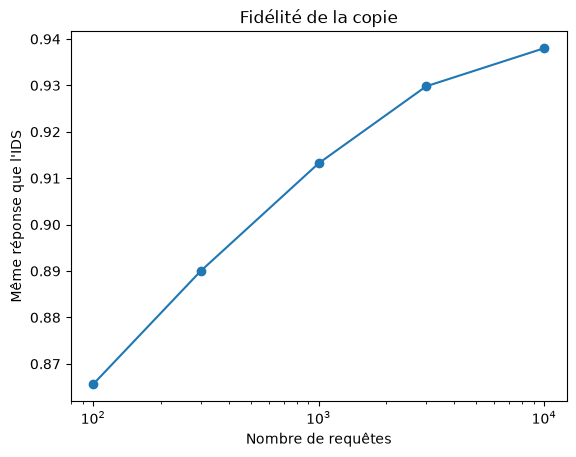

In [4]:
# Fidélité selon le nombre de requêtes
fidelite = {}
for n in [100, 300, 1000, 3000, 10000]:
    req = X_test.sample(n, random_state=1)
    c = RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1).fit(req, ids.predict(req))
    fidelite[n] = (c.predict(trafic_nouveau) == ids.predict(trafic_nouveau)).mean()

pd.Series(fidelite).plot(logx=True, marker='o', title='Fidélité de la copie', xlabel='Nombre de requêtes', ylabel='Même réponse que l\'IDS');

**👀 Ce qu'on doit voir :** avec **100** requêtes seulement, la copie est déjà fidèle à ≈ 87 %. Elle atteint ≈ 91 % à 1 000 requêtes et ≈ 94 % à 10 000. L'essentiel s'apprend très vite.

**Et là où ça compte ?** L'attaquant veut passer **près de la frontière** (la zone grise de l'ex. 1). La copie y est-elle aussi fidèle ?

In [5]:
confiance = ids.predict_proba(trafic_nouveau)[:, 1]
pres_frontiere = (confiance > 0.3) & (confiance < 0.7)

print(f"Fidélité en général         : {meme_reponse.mean():.0%}")
print(f"Fidélité près de la frontière : {meme_reponse[pres_frontiere].mean():.0%}")

Fidélité en général         : 93%
Fidélité près de la frontière : 14%


**👀 Ce qu'on doit voir :** ≈ 93 % en général, mais seulement ≈ 14 % près de la frontière. Là où l'attaquant en a besoin, la copie se trompe presque toujours.

**❓ Question pour la classe :** pourquoi la copie est-elle si mauvaise près de la frontière ? Comment l'attaquant pourrait-il choisir ses requêtes pour corriger ça ?

*Piste : seulement 2,5 % du trafic est en zone grise (ex. 1), donc la copie a vu très peu d'exemples à cet endroit. L'attaquant devrait concentrer ses requêtes autour des flux où la réponse bascule.*

## Étape 4 : Contre-mesure : limiter le nombre de requêtes
**Ce qu'on fait :** on ajoute un quota de 500 requêtes à l'API, puis on regarde si l'attaquant arrive quand même à faire une copie.

In [6]:
# <-- MODIFIABLE : le quota
api_protegee = API(ids, quota=500)

try:
    api_protegee.predire(X_test.sample(5000, random_state=1))
except PermissionError as e:
    print('Bloqué :', e)

# L'attaquant s'adapte : il reste sous le quota
req = X_test.sample(500, random_state=1)
copie_500 = RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1).fit(req, api_protegee.predire(req))
print(f"Copie avec seulement 500 requêtes : fidélité = {(copie_500.predict(trafic_nouveau) == ids.predict(trafic_nouveau)).mean():.0%}")

Bloqué : Quota dépassé : 0 requêtes déjà utilisées sur 500.


Copie avec seulement 500 requêtes : fidélité = 90%


**👀 Ce qu'on doit voir :** la demande de 5 000 requêtes est bloquée. Mais avec 500 requêtes, la copie est quand même fidèle à ≈ 90 %.

## Ce qu'il faut retenir
- Chaque réponse d'une API est un exemple d'entraînement gratuit pour l'attaquant.
- Quelques milliers de requêtes suffisent pour une copie fidèle à 93 %, mais **peu fidèle près de la frontière**.
- Le quota ralentit l'attaquant sans l'arrêter (il peut aussi utiliser plusieurs comptes). Autres défenses : ne jamais renvoyer la confiance, surveiller les clients qui envoient beaucoup de requêtes similaires.

**Exercice suivant :** l'attaquant a une copie. Il va l'**ouvrir** pour savoir quoi modifier.